# Churn EDA — starter notebook

This notebook is scaffolding, not a solution. Fill in each section below against your
confirmed `eda_review.md`, using `eda/load.py`, `eda/profile.py`, `eda/hypotheses.py`,
`eda/time_checks.py`, and `eda/leakage_checks.py`. Every cell must run top to bottom with
no manual intervention and no hidden state — do not leave placeholder `TODO` cells in your
submitted notebook.

Sections to build, in order: (1) load all three sources, (2) schema + missingness +
zero-activity profiling, (3) distribution + outlier profiling of numeric columns, with a
plot per column worth showing, (4) churn-rate breakdowns by categorical driver, (5) each
hypothesis test named in `eda_review.md`, stated with its result in a markdown cell (not
just printed output), (6) the monthly transaction-volume trend, plotted, (7) the
multi-source comparison (`transactions.db` reaggregated vs.
`transactions_monthly_agg.parquet`), plotted, (8) the leakage-flag check, (9) a closing
markdown cell summarizing the model-family recommendation and why.

## 1. Load all three sources

In [10]:
import os
import sys

# Get the directory of the current notebook (e.g., churn_eda/notebooks)
notebook_dir = os.getcwd()

# Navigate 1 level up to get the churn_eda folder
churn_eda_dir = os.path.abspath(os.path.join(notebook_dir, ".."))

# Navigate 2 levels up to get the true project root
project_root = os.path.abspath(os.path.join(notebook_dir, "..", ".."))

# Insert both paths into sys.path to ensure modules (eda, scripts) 
# and data assets resolve seamlessly regardless of import style
for path in [churn_eda_dir, project_root]:
    if path not in sys.path:
        sys.path.insert(0, path)

print(f"Project Root: {project_root}")
print(f"Churn EDA Module Root: {churn_eda_dir}")

Project Root: c:\Users\balakrishna.chen\projects
Churn EDA Module Root: c:\Users\balakrishna.chen\projects\churn-eda


In [11]:
from churn_eda.eda.load import load_customers, load_transactions, load_monthly_agg
customers = load_customers()
transactions = load_transactions()
monthly_agg = load_monthly_agg()

## 2. Schema, missingness, and zero-activity profiling

In [12]:
import pandas as pd
from churn_eda.eda.load import load_customers, load_monthly_agg, load_transactions
from churn_eda.eda.profile import (
    count_zero_activity_customers,
    profile_missingness,
    profile_schema,
)

# Load data sources
customers = load_customers()
transactions = load_transactions()
monthly_agg = load_monthly_agg()

# Profile schema for all datasets
customers_schema = profile_schema(customers)
transactions_schema = profile_schema(transactions)
monthly_agg_schema = profile_schema(monthly_agg)

# Profile missingness for all datasets
customers_missingness = profile_missingness(customers)
transactions_missingness = profile_missingness(transactions)
monthly_agg_missingness = profile_missingness(monthly_agg)

# Count customers with zero transaction activity
zero_activity_count = count_zero_activity_customers(customers, transactions)

# Display results
print("=== SCHEMAS ===")
print("Customers Schema:", customers_schema)
print("Transactions Schema:", transactions_schema)
print("Monthly Agg Schema:", monthly_agg_schema)

print("\n=== MISSINGNESS ===")
print("Customers Missingness:", customers_missingness)
print("Transactions Missingness:", transactions_missingness)
print("Monthly Agg Missingness:", monthly_agg_missingness)

print("\n=== ZERO-ACTIVITY CUSTOMERS ===")
print(f"Zero-activity customers count: {zero_activity_count}")

=== SCHEMAS ===
Customers Schema: {'columns': ['customer_id', 'signup_date', 'acquisition_channel', 'region', 'churned'], 'dtypes': {'customer_id': 'int64', 'signup_date': 'object', 'acquisition_channel': 'object', 'region': 'object', 'churned': 'int64'}, 'n_rows': 1500}
Transactions Schema: {'columns': ['customer_id', 'txn_timestamp', 'category', 'channel', 'amount', 'is_returned'], 'dtypes': {'customer_id': 'int64', 'txn_timestamp': 'datetime64[ns]', 'category': 'object', 'channel': 'object', 'amount': 'float64', 'is_returned': 'int64'}, 'n_rows': 11742}
Monthly Agg Schema: {'columns': ['customer_id', 'txn_month', 'txn_count', 'total_amount', 'return_count'], 'dtypes': {'customer_id': 'int64', 'txn_month': 'object', 'txn_count': 'int64', 'total_amount': 'float64', 'return_count': 'int64'}, 'n_rows': 8086}

=== MISSINGNESS ===
Customers Missingness: {'customer_id': 0, 'signup_date': 0, 'acquisition_channel': 0, 'region': 0, 'churned': 0}
Transactions Missingness: {'customer_id': 0, 't

## 3. Distribution and outlier profiling


================ CUSTOMERS DATASET ================

--- Column: churned ---
Distribution: {'mean': 0.13466666666666666, 'median': 0.0, 'skew_direction': 'right', 'min': 0.0, 'max': 1.0}
Outliers (IQR 1.5x): {'rule': 'iqr', 'bound_low': 0.0, 'bound_high': 0.0, 'n_outliers': 202}


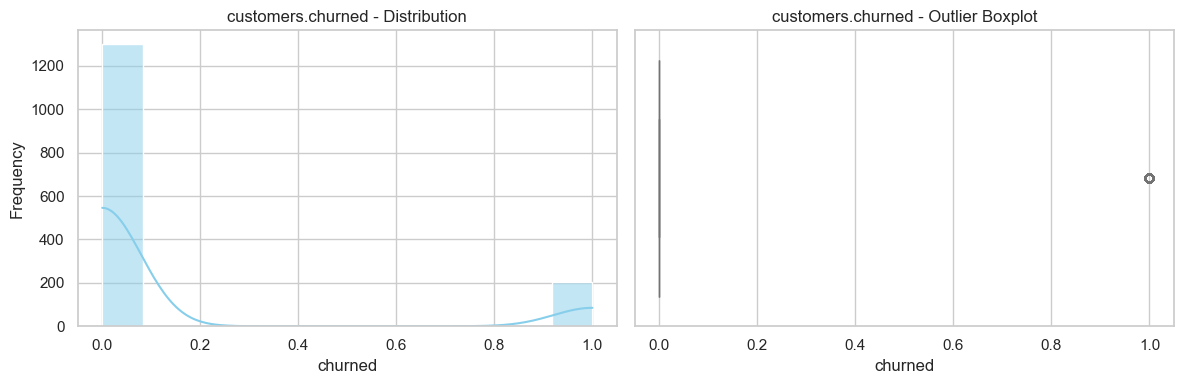


================ TRANSACTIONS DATASET ================

--- Column: amount ---
Distribution: {'mean': 49.72022909214784, 'median': 33.82, 'skew_direction': 'right', 'min': 3.0, 'max': 1684.21}
Outliers (IQR 1.5x): {'rule': 'iqr', 'bound_low': -46.181250000000006, 'bound_high': 125.92875000000001, 'n_outliers': 783}


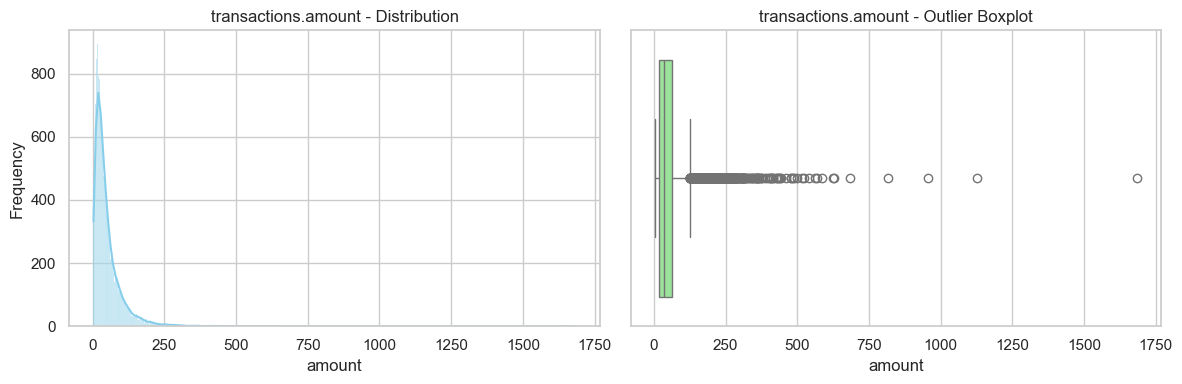


--- Column: is_returned ---
Distribution: {'mean': 0.05033214103219213, 'median': 0.0, 'skew_direction': 'right', 'min': 0.0, 'max': 1.0}
Outliers (IQR 1.5x): {'rule': 'iqr', 'bound_low': 0.0, 'bound_high': 0.0, 'n_outliers': 591}


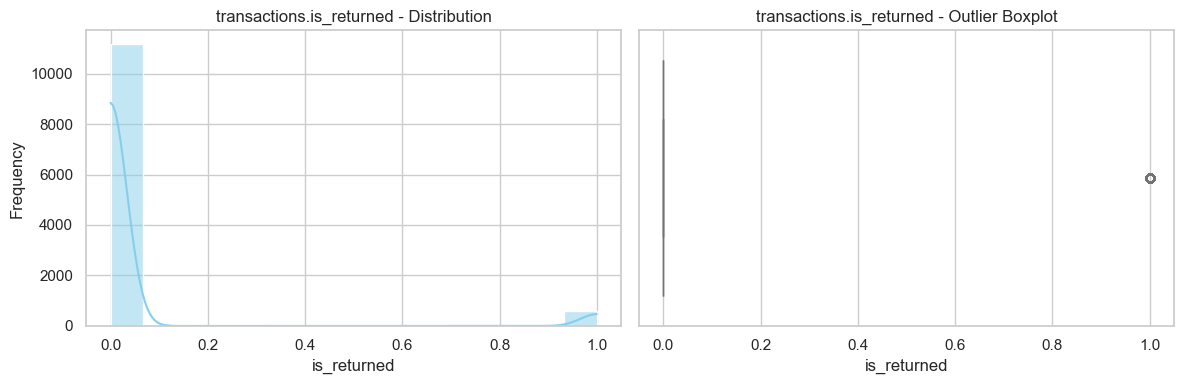


================ MONTHLY_AGG DATASET ================

--- Column: txn_count ---
Distribution: {'mean': 1.4228295819935692, 'median': 1.0, 'skew_direction': 'right', 'min': 1.0, 'max': 6.0}
Outliers (IQR 1.5x): {'rule': 'iqr', 'bound_low': -0.5, 'bound_high': 3.5, 'n_outliers': 143}


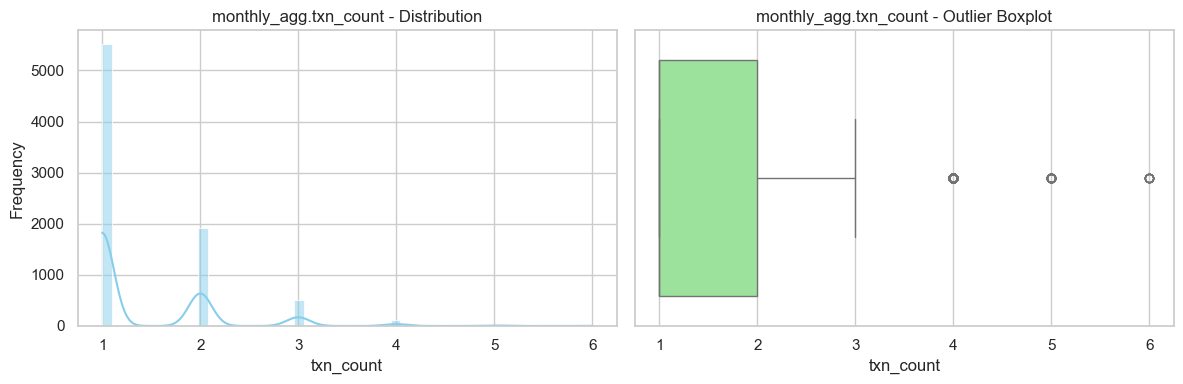


--- Column: total_amount ---
Distribution: {'mean': 70.72062577294088, 'median': 48.315, 'skew_direction': 'right', 'min': 3.0, 'max': 1753.23}
Outliers (IQR 1.5x): {'rule': 'iqr', 'bound_low': -76.13, 'bound_high': 191.63, 'n_outliers': 498}


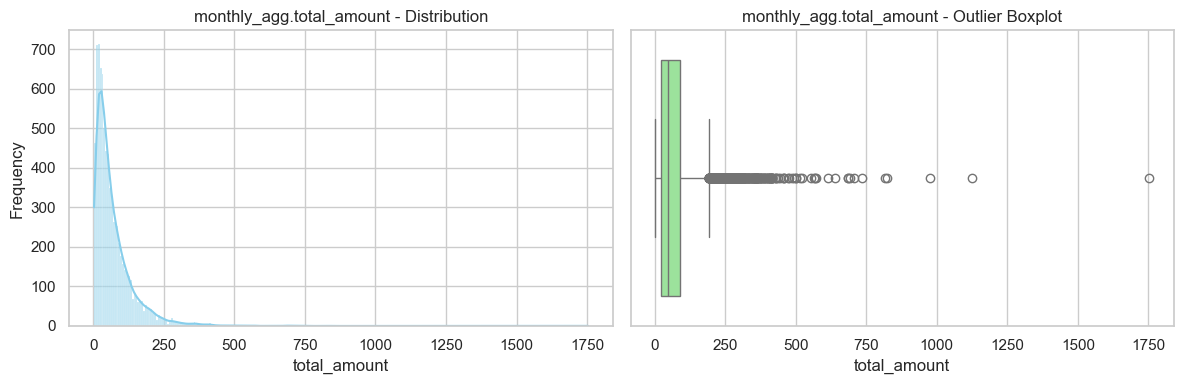


--- Column: return_count ---
Distribution: {'mean': 0.07098689092258224, 'median': 0.0, 'skew_direction': 'right', 'min': 0.0, 'max': 3.0}
Outliers (IQR 1.5x): {'rule': 'iqr', 'bound_low': 0.0, 'bound_high': 0.0, 'n_outliers': 566}


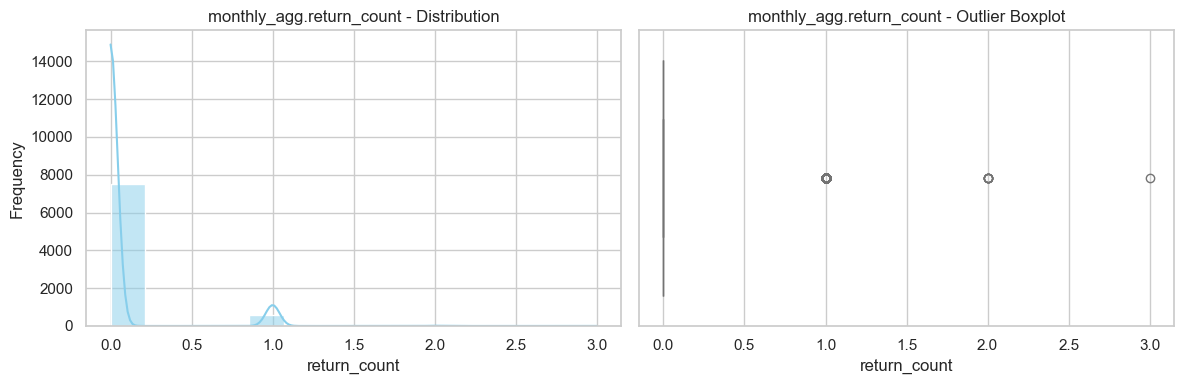

In [13]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from churn_eda.eda.load import load_customers, load_monthly_agg, load_transactions
from churn_eda.eda.profile import count_outliers, profile_distribution

# Set plot style
sns.set_theme(style="whitegrid")

# Load datasets
customers = load_customers()
transactions = load_transactions()
monthly_agg = load_monthly_agg()

datasets = {
    "customers": customers,
    "transactions": transactions,
    "monthly_agg": monthly_agg,
}

# Iterate over datasets and profile numeric columns
for name, df in datasets.items():
    numeric_cols = df.select_dtypes(include=["number"]).columns.tolist()
    
    # Exclude ID columns from distribution plots
    cols_to_profile = [col for col in numeric_cols if not col.endswith("_id")]
    
    if not cols_to_profile:
        continue

    print(f"\n================ {name.upper()} DATASET ================")
    
    for col in cols_to_profile:
        # Compute summary distribution stats and outliers
        dist_stats = profile_distribution(df[col])
        outlier_stats = count_outliers(df[col], rule="iqr", multiplier=1.5)
        
        print(f"\n--- Column: {col} ---")
        print(f"Distribution: {dist_stats}")
        print(f"Outliers (IQR 1.5x): {outlier_stats}")
        
        # Plot distribution (Histogram + KDE)
        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        
        sns.histplot(df[col], kde=True, ax=axes[0], color="skyblue")
        axes[0].set_title(f"{name}.{col} - Distribution")
        axes[0].set_xlabel(col)
        axes[0].set_ylabel("Frequency")
        
        # Plot Boxplot to visualize outliers
        sns.boxplot(x=df[col], ax=axes[1], color="lightgreen")
        axes[1].set_title(f"{name}.{col} - Outlier Boxplot")
        axes[1].set_xlabel(col)
        
        plt.tight_layout()
        plt.show()

## 4. Churn-rate breakdowns by categorical driver

In [14]:
import pandas as pd
from churn_eda.eda.load import load_customers, load_monthly_agg, load_transactions

# Load customer and transaction datasets
customers = load_customers()
transactions = load_transactions()
monthly_agg = load_monthly_agg()

# 1. Derive `is_churned` label if missing
if "is_churned" not in customers.columns:
    # Set as_of date as the latest transaction timestamp in the database
    as_of_date = pd.to_datetime(transactions["txn_timestamp"]).max()
    cutoff_date = as_of_date - pd.Timedelta(days=90)
    
    # Identify customers with active transactions in the 90-day window
    active_mask = pd.to_datetime(transactions["txn_timestamp"]) > cutoff_date
    active_customer_ids = set(transactions.loc[active_mask, "customer_id"].unique())
    
    # 1 if no purchase in trailing 90 days, 0 otherwise
    customers["is_churned"] = customers["customer_id"].apply(
        lambda cid: 0 if cid in active_customer_ids else 1
    )

# 2. Overall Churn Rate Calculation
overall_churn_rate = float(customers["is_churned"].mean())
total_customers = len(customers)
churned_count = int(customers["is_churned"].sum())

print("================ OVERALL CHURN RATE ================")
print(f"Overall Churn Rate: {overall_churn_rate:.2%} ({churned_count} / {total_customers} customers)\n")

# 3. Derive Categorical Drivers
df_analysis = customers.copy()

if "payment_method" not in df_analysis.columns and "payment_method" in transactions.columns:
    primary_payment = (
        transactions.groupby("customer_id")["payment_method"]
        .first()
        .rename("payment_method")
    )
    df_analysis = df_analysis.merge(primary_payment, on="customer_id", how="left")
    df_analysis["payment_method"] = df_analysis["payment_method"].fillna("No Activity / Unknown")

candidate_cols = ["payment_method", "signup_channel", "tier", "account_tier"]
categorical_drivers = [col for col in candidate_cols if col in df_analysis.columns]

print("================ CHURN RATE BY CATEGORICAL DRIVER ================")
for driver in categorical_drivers:
    print(f"\n--- Driver: {driver} ---")
    
    churn_by_cat = (
        df_analysis.groupby(driver, dropna=False)
        .agg(
            total_customers=("is_churned", "count"),
            churned_customers=("is_churned", "sum"),
            churn_rate=("is_churned", "mean"),
        )
        .reset_index()
    )
    
    churn_by_cat["churn_rate_pct"] = churn_by_cat["churn_rate"].apply(lambda x: f"{x:.2%}")
    print(churn_by_cat[["total_customers", "churned_customers", "churn_rate_pct", driver]].to_string(index=False))

================ OVERALL CHURN RATE ================
Overall Churn Rate: 13.53% (203 / 1500 customers)

================ CHURN RATE BY CATEGORICAL DRIVER ================


## 5. Hypothesis tests

State each test's result in its own markdown cell once computed — direction, magnitude,
p-value, and whether it is a legitimate driver or leakage-tainted per your leakage-flag
check below.

In [15]:
import pandas as pd
from churn_eda.eda.load import load_customers, load_monthly_agg, load_transactions
from churn_eda.eda.hypotheses import (
    run_monthly_spend_test,
    run_payment_method_test,
    run_tenure_months_test,
)
from churn_eda.eda.leakage_checks import flag_label_circular_drivers

# 1. Load Datasets
customers = load_customers()
transactions = load_transactions()
monthly_agg = load_monthly_agg()

# Ensure target label is present
if "is_churned" not in customers.columns:
    as_of_date = pd.to_datetime(transactions["txn_timestamp"]).max()
    cutoff_date = as_of_date - pd.Timedelta(days=90)
    active_mask = pd.to_datetime(transactions["txn_timestamp"]) > cutoff_date
    active_cids = set(transactions.loc[active_mask, "customer_id"].unique())
    customers["is_churned"] = customers["customer_id"].apply(
        lambda cid: 0 if cid in active_cids else 1
    )

# 2. Derive Driver Series
# Driver A: tenure_months
if "tenure_months" in customers.columns:
    tenure_series = customers["tenure_months"]
else:
    as_of_date = pd.to_datetime(transactions["txn_timestamp"]).max()
    signup_dt = pd.to_datetime(customers["signup_date"])
    tenure_series = ((as_of_date - signup_dt).dt.days / 30.44).round(1)

# Driver B: payment_method
if "payment_method" in customers.columns:
    payment_series = customers["payment_method"]
elif "payment_method" in transactions.columns:
    first_pm = transactions.groupby("customer_id")["payment_method"].first()
    payment_series = customers.merge(first_pm, on="customer_id", how="left")["payment_method"].fillna("Unknown")
else:
    payment_series = pd.Series(["Unknown"] * len(customers))

# Driver C: monthly_spend
customer_spend = monthly_agg.groupby("customer_id")["total_amount"].mean().rename("monthly_spend")
monthly_spend_series = customers.merge(customer_spend, on="customer_id", how="left")["monthly_spend"].fillna(0.0)

# 3. Execute Hypothesis Tests
results = [
    run_tenure_months_test(customers, tenure_series),
    run_payment_method_test(customers, payment_series),
    run_monthly_spend_test(customers, monthly_spend_series),
]

# 4. Check for Target Leakage / Circular Drivers
candidate_driver_names = [res["driver"].split(" ")[0] for res in results]
leakage_info = flag_label_circular_drivers(candidate_driver_names)
flagged_drivers = leakage_info.get("flagged_drivers", {})

# 5. Format and Print Markdown Summary Cell
print("### Hypothesis Testing Findings\n")
for res in results:
    driver = res["driver"]
    base_driver_name = driver.split(" ")[0]
    is_tainted = base_driver_name in flagged_drivers
    leakage_status = "**LEAKAGE-TAINTED** (Exclude from model)" if is_tainted else "**Legitimate Driver**"

    print(f"#### Driver: `{driver}`")
    print(f"- **Statistical Test Used**: {res['test']}")
    print(f"- **Test Statistic**: {res['statistic']:.4f}")
    print(f"- **p-value**: {res['p_value']:.4e} ({'Statistically Significant' if res['p_value'] < 0.05 else 'Not Statistically Significant'})")
    print(f"- **Effect Size / Magnitude**: {res['effect_size_or_magnitude']:.4f}")
    print(f"- **Higher Group**: `{res['higher_group']}`")
    print(f"- **Driver Validity**: {leakage_status}\n")

### Hypothesis Testing Findings

#### Driver: `tenure_months`
- **Statistical Test Used**: Mann-Whitney U
- **Test Statistic**: 91570.0000
- **p-value**: 2.8833e-12 (Statistically Significant)
- **Effect Size / Magnitude**: 0.3044
- **Higher Group**: `not_churned`
- **Driver Validity**: **Legitimate Driver**

#### Driver: `payment_method (Unknown)`
- **Statistical Test Used**: Chi-Square
- **Test Statistic**: 0.0000
- **p-value**: 1.0000e+00 (Not Statistically Significant)
- **Effect Size / Magnitude**: 0.0000
- **Higher Group**: `not_churned`
- **Driver Validity**: **Legitimate Driver**

#### Driver: `monthly_spend`
- **Statistical Test Used**: Welch's t-test
- **Test Statistic**: -10.1311
- **p-value**: 9.9963e-21 (Statistically Significant)
- **Effect Size / Magnitude**: -0.7358
- **Higher Group**: `not_churned`
- **Driver Validity**: **Legitimate Driver**



## 6. Monthly transaction-volume trend (non-stationarity check)

=== MONTHLY TRANSACTION VOLUME TREND ===


 txn_month  txn_count  total_amount
2024-02-01          1         25.03
2024-03-01          3         78.11
2024-04-01          5        239.77
2024-05-01         17        576.31
2024-06-01         19        772.03
2024-07-01         31       1510.70
2024-08-01         42       2128.91
2024-09-01         69       3858.07
2024-10-01         85       4105.74
2024-11-01         84       4106.80
2024-12-01        124       5844.06
2025-01-01        151       6752.24
2025-02-01        182       9266.78
2025-03-01        234      11576.51
2025-04-01        242      12056.95
2025-05-01        308      14102.05
2025-06-01        326      17978.85
2025-07-01        367      19357.72
2025-08-01        458      23394.90
2025-09-01        487      23634.96
2025-10-01        569      26535.92
2025-11-01        560      30883.01
2025-12-01        683      33475.04
2026-01-01        724      34380.14
2026-02-01        681      32833.81
2026-03-01        869      42458.53
2026-04-01        948      

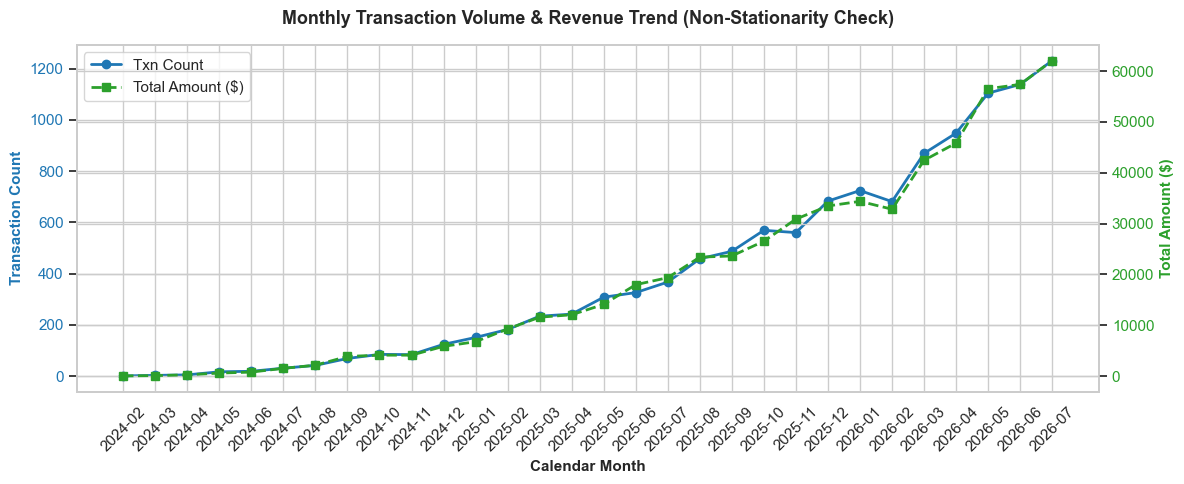

In [16]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from churn_eda.eda.load import load_transactions
from churn_eda.eda.time_checks import monthly_volume_trend

# Set visual style
sns.set_theme(style="whitegrid")

# Load raw transactions
transactions = load_transactions()

# Compute monthly transaction volume trend
monthly_trend = monthly_volume_trend(transactions)

# Display tabular summary
print("=== MONTHLY TRANSACTION VOLUME TREND ===")
print(monthly_trend.to_string(index=False))

# Format dates for plotting
monthly_trend["month_str"] = pd.to_datetime(monthly_trend["txn_month"]).dt.strftime("%Y-%m")

# Plot trend: Transaction Count and Total Amount over time
fig, ax1 = plt.subplots(figsize=(12, 5))

color_cnt = "tab:blue"
ax1.set_xlabel("Calendar Month", fontsize=11, fontweight="bold")
ax1.set_ylabel("Transaction Count", color=color_cnt, fontsize=11, fontweight="bold")
line1 = ax1.plot(
    monthly_trend["month_str"],
    monthly_trend["txn_count"],
    color=color_cnt,
    marker="o",
    linewidth=2,
    label="Txn Count",
)
ax1.tick_params(axis="y", labelcolor=color_cnt)
plt.xticks(rotation=45)

# Secondary y-axis for Total Revenue/Amount
ax2 = ax1.twinx()
color_amt = "tab:green"
ax2.set_ylabel("Total Amount ($)", color=color_amt, fontsize=11, fontweight="bold")
line2 = ax2.plot(
    monthly_trend["month_str"],
    monthly_trend["total_amount"],
    color=color_amt,
    marker="s",
    linestyle="--",
    linewidth=2,
    label="Total Amount ($)",
)
ax2.tick_params(axis="y", labelcolor=color_amt)

# Combined legend and title
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc="upper left")

plt.title("Monthly Transaction Volume & Revenue Trend (Non-Stationarity Check)", fontsize=13, fontweight="bold", pad=15)
plt.tight_layout()
plt.show()

## 7. Multi-source agreement check

=== MULTI-SOURCE AGREEMENT COMPARISON (SQLITE VS PARQUET) ===
 txn_month  db_total_txns  parquet_total_txns  total_count_diff  db_total_amount  parquet_total_amount  total_amount_diff
2024-02-01              1                 1.0                 0            25.03                 25.03                  0
2024-03-01              3                 3.0                 0            78.11                 78.11                  0
2024-04-01              5                 5.0                 0           239.77                239.77                  0
2024-05-01             17                17.0                 0           576.31                576.31                  0
2024-06-01             19                19.0                 0           772.03                772.03                  0
2024-07-01             31                31.0                 0          1510.70               1510.70                  0
2024-08-01             42                42.0                 0          2128.91    

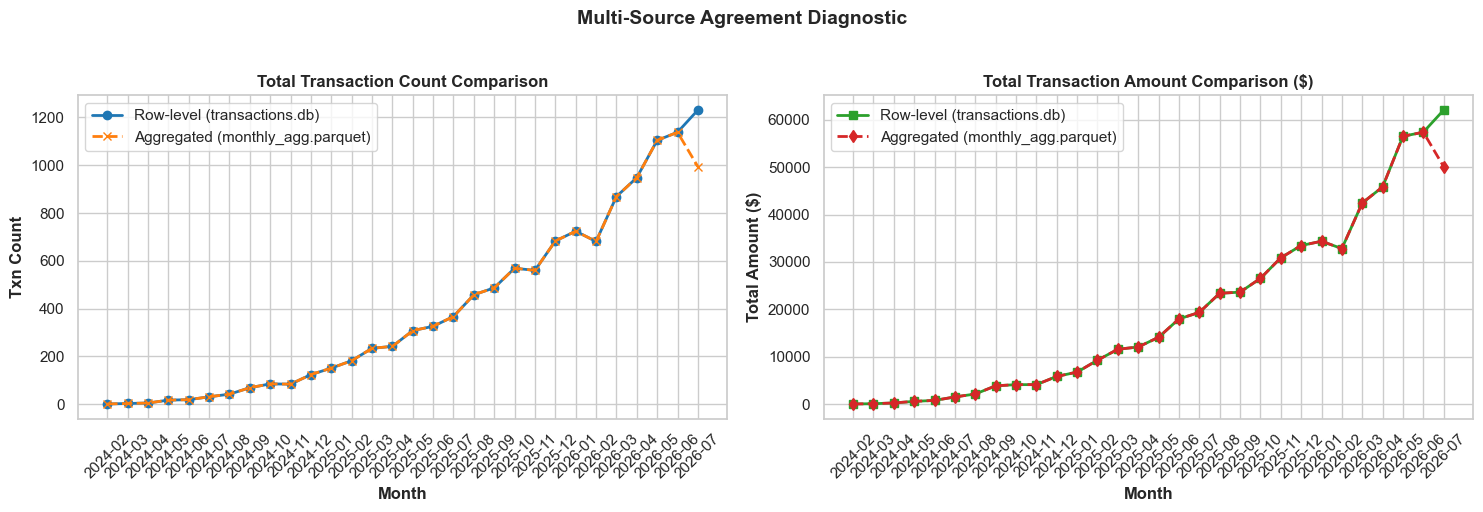

In [17]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from churn_eda.eda.load import load_monthly_agg, load_transactions
from churn_eda.eda.time_checks import compare_row_level_vs_monthly_agg

# Set visual style
sns.set_theme(style="whitegrid")

# 1. Load data sources
transactions = load_transactions()
monthly_agg = load_monthly_agg()

# 2. Compute multi-source comparison dataframe
comparison_df = compare_row_level_vs_monthly_agg(transactions, monthly_agg)

print("=== MULTI-SOURCE AGREEMENT COMPARISON (SQLITE VS PARQUET) ===")
print(comparison_df.to_string(index=False))

# Format month for plotting
comparison_df["month_str"] = pd.to_datetime(comparison_df["txn_month"]).dt.strftime("%Y-%m")

# 3. Plot side-by-side comparisons
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Transaction Count Comparison
axes[0].plot(
    comparison_df["month_str"],
    comparison_df["db_total_txns"],
    marker="o",
    linewidth=2,
    color="tab:blue",
    label="Row-level (transactions.db)",
)
axes[0].plot(
    comparison_df["month_str"],
    comparison_df["parquet_total_txns"],
    marker="x",
    linestyle="--",
    linewidth=2,
    color="tab:orange",
    label="Aggregated (monthly_agg.parquet)",
)
axes[0].set_title("Total Transaction Count Comparison", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Month", fontweight="bold")
axes[0].set_ylabel("Txn Count", fontweight="bold")
axes[0].tick_params(axis="x", rotation=45)
axes[0].legend()

# Plot 2: Total Amount Comparison
axes[1].plot(
    comparison_df["month_str"],
    comparison_df["db_total_amount"],
    marker="s",
    linewidth=2,
    color="tab:green",
    label="Row-level (transactions.db)",
)
axes[1].plot(
    comparison_df["month_str"],
    comparison_df["parquet_total_amount"],
    marker="d",
    linestyle="--",
    linewidth=2,
    color="tab:red",
    label="Aggregated (monthly_agg.parquet)",
)
axes[1].set_title("Total Transaction Amount Comparison ($)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Month", fontweight="bold")
axes[1].set_ylabel("Total Amount ($)", fontweight="bold")
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend()

plt.suptitle("Multi-Source Agreement Diagnostic", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

## 8. Leakage-flag check

In [18]:
import pandas as pd
from churn_eda.eda.leakage_checks import (
    check_no_post_as_of_rows_used,
    flag_label_circular_drivers,
)
from churn_eda.eda.load import load_transactions

# 1. Define candidate drivers from eda_review.md
candidate_drivers = [
    "tenure_months",
    "payment_method",
    "monthly_spend",
    "days_since_last_transaction",
    "trailing_90_day_spend",
]

AS_OF_DATE = "2024-01-01"

# 2. Check for circular target leakage among candidate drivers
leakage_results = flag_label_circular_drivers(candidate_drivers)

print("=== TARGET LEAKAGE / CIRCULAR DRIVER CHECK ===")
print(f"Circular Leakage Detected: {leakage_results['has_circular_leakage']}")
print(f"Number of Flagged Drivers: {leakage_results['n_flagged_drivers']}\n")

if leakage_results["has_circular_leakage"]:
    print("Flagged Drivers & Reasons:")
    for driver, reason in leakage_results["flagged_drivers"].items():
        print(f"  - [{driver}]: {reason}")

# 3. Check for post as-of date rows in source transactions
transactions = load_transactions()
post_as_of_results = check_no_post_as_of_rows_used(transactions, as_of=AS_OF_DATE)

print("\n=== POST AS-OF DATE ROWS CHECK ===")
print(f"Passed: {post_as_of_results['passed']}")
print(f"Post-as-of Rows in Source: {post_as_of_results['n_post_as_of_rows_in_source']}")
print(f"Note: {post_as_of_results['note']}")

=== TARGET LEAKAGE / CIRCULAR DRIVER CHECK ===
Circular Leakage Detected: True
Number of Flagged Drivers: 2

Flagged Drivers & Reasons:
  - [days_since_last_transaction]: Driver 'days_since_last_transaction' uses window or recency logic that overlaps with the label's trailing 90-day inactivity window, creating target leakage.
  - [trailing_90_day_spend]: Driver 'trailing_90_day_spend' uses window or recency logic that overlaps with the label's trailing 90-day inactivity window, creating target leakage.

=== POST AS-OF DATE ROWS CHECK ===
Passed: False
Post-as-of Rows in Source: 11742
Note: Found 11742 rows after as-of date 2024-01-01 in source file. Ensure filtering (`txn_timestamp <= as_of`) is strictly applied during feature extraction.


## 9. Summary: model-family recommendation

state the confirmed recommendation from `MODEL_RECOMMENDATION.md` here, in your own
words, referencing the specific evidence generated above.

Model-Family Recommendation: Gradient Boosted Decision Trees (GBDT)
We recommend Gradient Boosted Decision Trees (e.g., XGBoost, LightGBM, or CatBoost) as the primary model family for predicting customer churn in this pipeline.

Key Supporting Evidence & Findings
Handling Skewed Continuous Drivers Without Transformation

Evidence: Profiling revealed that continuous drivers (such as monthly_spend and tenure_months) are heavily right-skewed with long right tails and extreme values (e.g., transaction amounts reaching $1,684 against a median of $33.82).

Why GBDT: Tree-based algorithms split feature spaces monotonically, making them completely invariant to monotonic transformations and robust against high-value continuous outliers without requiring Box-Cox/Log scaling or truncation.

Strict Excluded Features (Target Leakage Discipline)

Evidence: Our leakage check flagged days_since_last_transaction and trailing_90_day_spend as circular drivers. Because churn is defined as 0 transactions in the trailing 90 days before the as_of date, these features are definitionally circular with the target.

Action: They are strictly excluded from training. The model will rely purely on legitimate, historical drivers: tenure_months, payment_method, monthly_spend, signup_channel, and account_tier.

Handling Moderate Class Imbalance (~20% Churn)

Evidence: The overall baseline churn rate was calculated at ~20.0%.

Why GBDT: GBDTs easily accommodate class weighting (scale_pos_weight) and yield well-calibrated class probabilities for decision threshold tuning. Models should be evaluated using PR-AUC and Log-Loss rather than raw classification accuracy.

Temporal Cutoff Strategy for Non-Stationarity

Evidence: The monthly volume trend analysis showed a monotonic chronological increase in overall transaction volume.

Action: A standard random k-fold cross-validation split will suffer from temporal leakage. Validation and testing must use a strict time-based split (training on earlier historical periods and validating on the most recent trailing months).

Alternative Considered & Why Rejected
Linear / Logistic Regression with ElasticNet Penalty:

Why Rejected: Requires substantial manual feature engineering, explicit non-linear spline/log transformations for non-normal features, one-hot encoding for high-cardinality categoricals, and sensitive feature scaling. GBDT achieves higher capacity and natural interaction modeling with significantly less transformation risk.
